In [1]:
import numpy as np
import pandas as pd
import nibabel as nib
from scipy.spatial.distance import euclidean
from scipy.stats import wilcoxon
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

In [2]:
def flat_without_diagonal(matrix):

    matrix = matrix.copy()
    n = matrix.shape[0]
    upper = matrix[np.triu_indices(n, k =  1)]
    lower = matrix[np.tril_indices(n, k = -1)]
    
    return np.concatenate([upper, lower])

In [ ]:
def binarize(W, percentile, zero_diagonal = True, directed = True):
    
    W = W.copy(); W = abs(W)
    if zero_diagonal: np.fill_diagonal(W, 0)
    if directed == False: W = np.array([[max(W[i, j], W[j, i]) for j in range(W.shape[1])] for i in range(W.shape[0])])

    if zero_diagonal: thre = np.percentile(flat_without_diagonal(W), percentile)
    else: thre = np.percentile(W, percentile)
    
    W[W < thre] = 0; W[W > 0] = 1

    return W

In [4]:
def sigbar(x1, x2, y, p, fontsize = 10, lw = 1.5):

    plt.hlines(y, x1, x2, lw = lw, colors = 'k')
    if p < 0.001: text = '***'
    elif p < 0.01: text = '**'
    elif p < 0.05: text = '*'
    else: text = 'n.s.'
    plt.text(x = (x1+x2)/2, y = y, s = text, fontsize = fontsize, ha = 'center', va = 'bottom')

#### MMP

In [28]:
atlas_gii_surf_L = nib.load('../results/fig04/S1200.L.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf_R = nib.load('../results/fig04/S1200.R.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf = np.vstack([atlas_gii_surf_L, atlas_gii_surf_R])
atlas_gii_label_L = nib.load('../results/fig04/L.Glasser2016.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R = nib.load('../results/fig04/R.Glasser2016.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R[atlas_gii_label_R != 0] += 1000
atlas_gii_label = np.hstack([atlas_gii_label_L, atlas_gii_label_R])

roi_labels = np.unique(atlas_gii_label); roi_labels = sorted(roi_labels[roi_labels != 0])
centroids = [np.mean(atlas_gii_surf[np.argwhere(atlas_gii_label == label).flatten()], axis = 0) for label in roi_labels]
distance = np.zeros((len(roi_labels), len(roi_labels)))
distance = np.array([[euclidean(centroids[i], centroids[j]) for j in range(len(roi_labels))] for i in range(len(roi_labels))])

cost_min_thre = np.percentile(flat_without_diagonal(distance), 15); cost_min = np.sum(distance[distance < cost_min_thre]) / np.sum(distance)
cost_max_thre = np.percentile(flat_without_diagonal(distance), 85); cost_max = np.sum(distance[distance > cost_max_thre]) / np.sum(distance)
effi_min = 1.0 * 0.15 + 0.0 * 0.85
effi_max = 1.0 * 0.15 + 0.5 * 0.85

In [6]:
res_pareto  = pd.read_csv('../results/fig04/graphical_res_pareto_MMP.csv')
res_human   = pd.read_csv('../results/fig04/graphical_res_HCP_MMP(distance_ridge).csv')
res_human70 = res_human[abs(res_human['lambda'] - 0.7) < 1e-3]

optimization_degree = ((cost_max-res_pareto['global_cost'].values)/(cost_max-cost_min) + (res_pareto['global_effi'].values-effi_min)/(effi_max-effi_min)) / 2
optimal_idx = np.where(optimization_degree == np.max(optimization_degree))[0][0]

human_effi = res_human[abs(res_human['lambda'] - 0.7) < 1e-3]['global_effi'].values
effiavg_idx = np.where(abs(res_pareto['global_effi'].values - np.mean(human_effi)) == np.min(abs(res_pareto['global_effi'].values - np.mean(human_effi))))[0][0]

human_cost = res_human[abs(res_human['lambda'] - 0.7) < 1e-3]['global_cost'].values
costavg_idx = np.where(abs(res_pareto['global_cost'].values - np.mean(human_cost)) == np.min(abs(res_pareto['global_cost'].values - np.mean(human_cost))))[0][0]

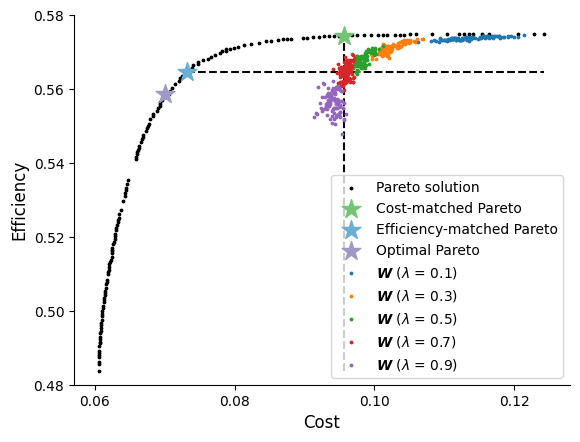

In [7]:
res = res_pareto.to_dict(orient = 'list')
plt.scatter(np.array(res['global_cost']), np.array(res['global_effi']), color = 'black', s = 3, zorder = 2, label = 'Pareto solution')
plt.scatter(np.array(res['global_cost'])[costavg_idx], np.array(res['global_effi'])[costavg_idx], color = plt.get_cmap('tab20c').colors[ 9], marker = '*', s = 200, zorder = 3, label = 'Cost-matched Pareto')
plt.scatter(np.array(res['global_cost'])[effiavg_idx], np.array(res['global_effi'])[effiavg_idx], color = plt.get_cmap('tab20c').colors[ 1], marker = '*', s = 200, zorder = 3, label = 'Efficiency-matched Pareto')
plt.scatter(np.array(res['global_cost'])[optimal_idx], np.array(res['global_effi'])[optimal_idx], color = plt.get_cmap('tab20c').colors[13], marker = '*', s = 200, zorder = 3, label = 'Optimal Pareto')
plt.vlines(np.array(res['global_cost'])[costavg_idx], np.min(np.array(res['global_effi'])), np.array(res['global_effi'])[costavg_idx], color = 'k', linestyles = '--', linewidth = 1.5, zorder = 2)
plt.hlines(np.array(res['global_effi'])[effiavg_idx], np.array(res['global_cost'])[effiavg_idx], np.max(np.array(res['global_cost'])), color = 'k', linestyles = '--', linewidth = 1.5, zorder = 2)

res = res_human
for i in range(5):
    lam = 0.2 * i + 0.1
    filtered_res = res[abs(res['lambda'] - lam) < 1e-3]
    plt.scatter(filtered_res['global_cost'].values, filtered_res['global_effi'].values, color = plt.get_cmap('tab10').colors[i], s = 3, zorder = 2, label = r'$\boldsymbol{W}$ '+r'($\lambda$ = {:.1f})'.format(lam))

ax = plt.gca(); ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlabel('Cost', fontsize = 12); plt.xlim(0.057, 0.128); plt.xticks([0.06, 0.08, 0.10, 0.12], fontsize = 10)
plt.ylabel('Efficiency', fontsize = 12); plt.ylim(0.480, 0.580); plt.yticks([0.48, 0.50, 0.52, 0.54, 0.56, 0.58], fontsize = 10)
plt.legend(loc = 'lower right', fontsize = 10)

plt.show()

In [8]:
lambdas = np.linspace(0.10, 0.90, 41)
temp = res_human[(res_human['lambda'] > 0.1-1e-3) & (res_human['lambda'] < 0.9+1e-3)].to_dict(orient = 'list')
temp = {'FILE_ID': temp['FILE_ID'], 'lambda': temp['lambda'], 'global_cost': temp['global_cost'], 'global_effi': temp['global_effi']}
temp['optimization_degree'] = list(((cost_max-np.array(temp['global_cost']))/(cost_max-cost_min) + (np.array(temp['global_effi'])-effi_min)/(effi_max-effi_min)) / 2)

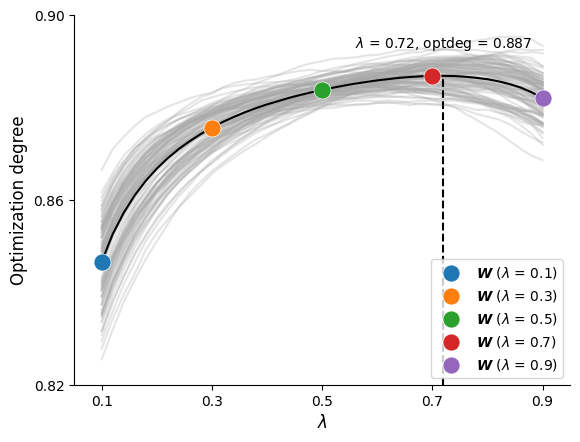

In [9]:
summary = pd.DataFrame(temp).groupby('lambda').agg(['mean', 'std'])['optimization_degree']
idx = np.where(summary['mean'].values == np.max(summary['mean'].values))[0][0]
plt.vlines(lambdas[idx], ymin = 0.82, ymax = summary['mean'].values[idx], color = 'k', linestyle = '--', zorder = 2)

v_mean = summary['mean'].values; v_std = summary['std'].values
plt.plot(lambdas, v_mean, color = 'k', zorder = 2)
for sub in np.unique(res_human['FILE_ID'].values):
    df = pd.DataFrame(temp)
    sub_temp = np.array(df[(df['FILE_ID'] == sub) & (df['lambda'] > 0.1-1e-3) & (df['lambda'] < 0.9+1e-3)]['optimization_degree'])
    plt.plot(lambdas, sub_temp, color = 'darkgray', alpha = 0.3, zorder = 1)
for lam in np.linspace(0.1, 0.9, 5):
    plt.scatter(lam, v_mean[np.where(abs(lambdas-lam)<1e-3)[0][0]], c = [plt.get_cmap('tab10').colors[round((lam*10-1)/2)]], zorder = 3, s = 150, lw = .5, edgecolors = 'white', label = r'$\boldsymbol{W}$ '+r'($\lambda$ = {:.1f})'.format(lam))
plt.text(x = lambdas[idx], y = 0.893, s = r'$\lambda$ = {:.2f}, optdeg = {:.3f}'.format(lambdas[idx], summary['mean'].values[idx]), ha = 'center', fontsize = 10)

ax = plt.gca(); ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlabel(r'$\lambda$', fontsize = 12); plt.xlim(0.050, 0.950); plt.xticks([0.1, 0.3, 0.5, 0.7, 0.9], fontsize = 10)
plt.ylabel('Optimization degree', fontsize = 12); plt.ylim(0.820, 0.900); plt.yticks([0.82, 0.86, 0.90], fontsize = 10)
plt.legend(loc = 'lower right', fontsize = 10)

plt.show()

In [10]:
Wlist = np.load('../results/fig04/indiv_W_HCP_MMP(distance_ridge_0.70).npz')['arr_0']
binWlist = np.array([binarize(Wlist[i], 85) for i in range(Wlist.shape[0])])

pareto_costavg = np.load('../results/fig04/W_pareto_MMP.npz')['arr_0'][costavg_idx]
pareto_effiavg = np.load('../results/fig04/W_pareto_MMP.npz')['arr_0'][effiavg_idx]
pareto_optimal = np.load('../results/fig04/W_pareto_MMP.npz')['arr_0'][optimal_idx]

costavg_match = np.array([(2 * np.sum(flat_without_diagonal(binWlist[idx]) * flat_without_diagonal(pareto_costavg))) / (np.sum(flat_without_diagonal(binWlist[idx])) + np.sum(flat_without_diagonal(pareto_costavg))) for idx in range(binWlist.shape[0])])
effiavg_match = np.array([(2 * np.sum(flat_without_diagonal(binWlist[idx]) * flat_without_diagonal(pareto_effiavg))) / (np.sum(flat_without_diagonal(binWlist[idx])) + np.sum(flat_without_diagonal(pareto_effiavg))) for idx in range(binWlist.shape[0])])
optimal_match = np.array([(2 * np.sum(flat_without_diagonal(binWlist[idx]) * flat_without_diagonal(pareto_optimal))) / (np.sum(flat_without_diagonal(binWlist[idx])) + np.sum(flat_without_diagonal(pareto_optimal))) for idx in range(binWlist.shape[0])])

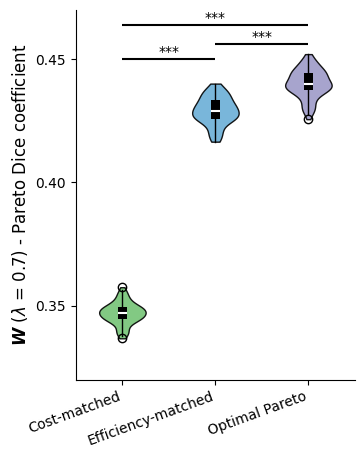

In [11]:
res = [costavg_match, effiavg_match, optimal_match]
colors = [plt.get_cmap('tab20c').colors[i] for i in [9, 1, 13]]

plt.figure(figsize = (3.6, 4.8)); ax = plt.gca()

vp = ax.violinplot(res, showextrema = False)
for i, body in enumerate(vp['bodies']):
    body.set_facecolor(colors[i])
    body.set_edgecolor('black')
    body.set_alpha(0.9)

box = ax.boxplot(res, widths = 0.1, patch_artist = True, positions = np.arange(1, 4), showcaps = False)
for patch in box['boxes']: patch.set(facecolor = 'black', linewidth = 0)
for median in box['medians']: median.set(color = 'white', linewidth = 1.5)

pvals = [wilcoxon(res[0], res[1])[1], wilcoxon(res[1], res[2])[1], wilcoxon(res[0], res[2])[1]]
_, qvals, _, _ = multipletests(pvals, alpha = 0.05, method = 'bonferroni')
sigbar(1, 2, 0.450, qvals[0])
sigbar(2, 3, 0.456, qvals[1])
sigbar(1, 3, 0.464, qvals[2])

ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xticks([1, 2, 3], ['Cost-matched', 'Efficiency-matched', 'Optimal Pareto'], rotation = 20, ha = 'right', fontsize = 10)
plt.ylabel(r'$\boldsymbol{W}$ ($\lambda$ = 0.7) - Pareto Dice coefficient', fontsize = 12); plt.ylim(0.32, 0.47); plt.yticks([0.35, 0.40, 0.45], fontsize = 10)

plt.show()

In [12]:
res = [res_human70['intra_effi'].values, [res_pareto['intra_effi'].values[costavg_idx]], [res_pareto['intra_effi'].values[effiavg_idx]], [res_pareto['intra_effi'].values[optimal_idx]]]

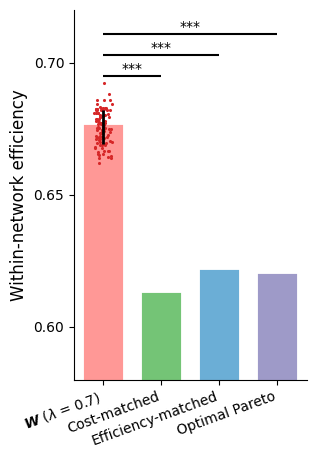

In [13]:
plt.figure(figsize = (3.0, 4.8)); ax = plt.gca()

plt.bar([0], [np.mean(res[0])], width = 0.6, color = plt.get_cmap('tab20' ).colors[ 7], edgecolor = plt.get_cmap('tab20' ).colors[ 7], linewidth = 3, zorder = 1)
plt.bar([1], [np.mean(res[1])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 9], edgecolor = plt.get_cmap('tab20c').colors[ 9], linewidth = 3, zorder = 1)
plt.bar([2], [np.mean(res[2])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 1], edgecolor = plt.get_cmap('tab20c').colors[ 1], linewidth = 3, zorder = 1)
plt.bar([3], [np.mean(res[3])], width = 0.6, color = plt.get_cmap('tab20c').colors[13], edgecolor = plt.get_cmap('tab20c').colors[13], linewidth = 3, zorder = 1)
plt.bar([0, 1, 2, 3], [np.mean(temp) for temp in res], yerr = [np.std(res[0]), 0, 0, 0], alpha = 0, zorder = 3, error_kw = {'elinewidth': 2})
jittered_x = 0 + np.random.uniform(-0.15, 0.15, size = len(res[0]))
ax.scatter(x = jittered_x, y = res[0], color = plt.get_cmap('tab20').colors[6], s = 5, linewidths = 0, zorder = 2)

pvals = [wilcoxon(res[0] - res[i][0])[1] for i in range(1, len(res))]
_, qvals, _, _ = multipletests(pvals, alpha = 0.05, method = 'bonferroni')
for i in range(1, len(res)): sigbar(0, i, 0.695+(i-1)*0.008, qvals[i-1])

ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlim(-0.5, 3.5); plt.xticks([0, 1, 2, 3], [r'$\boldsymbol{W}$ ($\lambda$ = 0.7)', 'Cost-matched', 'Efficiency-matched', 'Optimal Pareto'], rotation = 20, ha = 'right', fontsize = 10)
plt.ylabel('Within-network efficiency', fontsize = 12); plt.ylim(0.58, 0.72); plt.yticks([0.60, 0.65, 0.70], fontsize = 10)

plt.show()

In [14]:
res = [res_human70['inter_effi'].values, [res_pareto['inter_effi'].values[costavg_idx]], [res_pareto['inter_effi'].values[effiavg_idx]], [res_pareto['inter_effi'].values[optimal_idx]]]

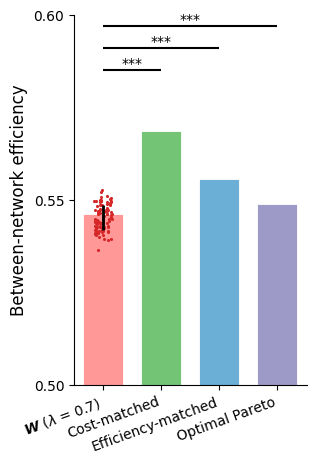

In [15]:
plt.figure(figsize = (3.0, 4.8)); ax = plt.gca()

plt.bar([0], [np.mean(res[0])], width = 0.6, color = plt.get_cmap('tab20' ).colors[ 7], edgecolor = plt.get_cmap('tab20' ).colors[ 7], linewidth = 3, zorder = 1)
plt.bar([1], [np.mean(res[1])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 9], edgecolor = plt.get_cmap('tab20c').colors[ 9], linewidth = 3, zorder = 1)
plt.bar([2], [np.mean(res[2])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 1], edgecolor = plt.get_cmap('tab20c').colors[ 1], linewidth = 3, zorder = 1)
plt.bar([3], [np.mean(res[3])], width = 0.6, color = plt.get_cmap('tab20c').colors[13], edgecolor = plt.get_cmap('tab20c').colors[13], linewidth = 3, zorder = 1)
plt.bar([0, 1, 2, 3], [np.mean(temp) for temp in res], yerr = [np.std(res[0]), 0, 0, 0], alpha = 0, zorder = 3, error_kw = {'elinewidth': 2})
jittered_x = 0 + np.random.uniform(-0.15, 0.15, size = len(res[0]))
ax.scatter(x = jittered_x, y = res[0], color = plt.get_cmap('tab20').colors[6], s = 5, linewidths = 0, zorder = 2)

pvals = [wilcoxon(res[0] - res[i][0])[1] for i in range(1, len(res))]
_, qvals, _, _ = multipletests(pvals, alpha = 0.05, method = 'bonferroni')
for i in range(1, len(res)): sigbar(0, i, 0.585+(i-1)*0.006, qvals[i-1])

ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlim(-0.5, 3.5); plt.xticks([0, 1, 2, 3], [r'$\boldsymbol{W}$ ($\lambda$ = 0.7)', 'Cost-matched', 'Efficiency-matched', 'Optimal Pareto'], rotation = 20, ha = 'right', fontsize = 10)
plt.ylabel('Between-network efficiency', fontsize = 12); plt.ylim(0.50, 0.60); plt.yticks([0.50, 0.55, 0.60], fontsize = 10)

plt.show()

In [16]:
sublist = np.unique(res_human70['FILE_ID'])
edge_human = np.array([[res_human70[res_human70['FILE_ID'] == sub]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)] for sub in sublist])
edge_human = edge_human / np.array([res_human70[res_human70['FILE_ID'] == sub]['global_effi'].to_list()[0] for sub in sublist]).reshape(-1, 1)
edge_human = np.hstack([np.ones((edge_human.shape[0], 1)), edge_human, np.zeros((edge_human.shape[0], 1))])
edge_human_avg = np.mean(edge_human, axis = 0); edge_human_std = np.std(edge_human, axis = 0)

edge_pareto_costavg = np.array([res_pareto[res_pareto['index'] == costavg_idx]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)])
edge_pareto_costavg = edge_pareto_costavg / res_pareto[res_pareto['index'] == costavg_idx]['global_effi'].to_list()[0]
edge_pareto_costavg = np.array([1] + list(edge_pareto_costavg) + [0])

edge_pareto_effiavg = np.array([res_pareto[res_pareto['index'] == effiavg_idx]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)])
edge_pareto_effiavg = edge_pareto_effiavg / res_pareto[res_pareto['index'] == effiavg_idx]['global_effi'].to_list()[0]
edge_pareto_effiavg = np.array([1] + list(edge_pareto_effiavg) + [0])

edge_pareto_optimal = np.array([res_pareto[res_pareto['index'] == optimal_idx]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)])
edge_pareto_optimal = edge_pareto_optimal / res_pareto[res_pareto['index'] == optimal_idx]['global_effi'].to_list()[0]
edge_pareto_optimal = np.array([1] + list(edge_pareto_optimal) + [0])

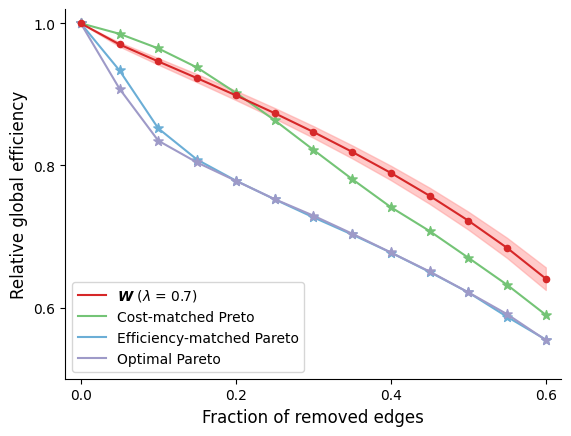

In [17]:
plt.plot(np.linspace(0, 1, 21)[:13], edge_human_avg[:13], zorder = 4, color = plt.get_cmap('tab20').colors[6], label = r'$\boldsymbol{W}$ ($\lambda$ = 0.7)')
plt.fill_between(np.linspace(0, 1, 21)[:13], edge_human_avg[:13] - edge_human_std[:13], edge_human_avg[:13] + edge_human_std[:13], zorder = 1, color = plt.get_cmap('tab20').colors[7], alpha = 0.5)
plt.scatter(np.linspace(0, 1, 21)[:13], edge_human_avg[:13], zorder = 4, color = plt.get_cmap('tab20').colors[6], s = 20)

plt.plot(np.linspace(0, 1, 21)[:13], edge_pareto_costavg[:13], zorder = 1, color = plt.get_cmap('tab20c').colors[9], label = 'Cost-matched Preto')
plt.scatter(np.linspace(0, 1, 21)[:13], edge_pareto_costavg[:13], zorder = 1, color = plt.get_cmap('tab20c').colors[9], s = 50, marker = '*')

plt.plot(np.linspace(0, 1, 21)[:13], edge_pareto_effiavg[:13], zorder = 2, color = plt.get_cmap('tab20c').colors[1], label = 'Efficiency-matched Pareto')
plt.scatter(np.linspace(0, 1, 21)[:13], edge_pareto_effiavg[:13], zorder = 2, color = plt.get_cmap('tab20c').colors[1], s = 50, marker = '*')

plt.plot(np.linspace(0, 1, 21)[:13], edge_pareto_optimal[:13], zorder = 3, color = plt.get_cmap('tab20c').colors[13], label = 'Optimal Pareto')
plt.scatter(np.linspace(0, 1, 21)[:13], edge_pareto_optimal[:13], zorder = 3, color = plt.get_cmap('tab20c').colors[13], s = 50, marker = '*')

ax = plt.gca(); ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlabel('Fraction of removed edges', fontsize = 12); plt.xlim(-0.02, 0.62); plt.xticks([0.0, 0.2, 0.4, 0.6], fontsize = 10)
plt.ylabel('Relative global efficiency', fontsize = 12); plt.ylim(0.50, 1.02); plt.yticks([0.6, 0.8, 1.0], fontsize = 10)
plt.legend(loc = 'lower left', fontsize = 10)

plt.show()

#### Schaefer200

In [18]:
atlas_gii_surf_L = nib.load('../results/fig04/S1200.L.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf_R = nib.load('../results/fig04/S1200.R.pial_MSMAll.10k_fs_LR.surf.gii').darrays[0].data
atlas_gii_surf = np.vstack([atlas_gii_surf_L, atlas_gii_surf_R])
atlas_gii_label_L = nib.load('../results/fig04/L.Schaefer2018_200Parcels_7Networks_order.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R = nib.load('../results/fig04/R.Schaefer2018_200Parcels_7Networks_order.human.10k_fs_LR.label.gii').darrays[0].data
atlas_gii_label_R[atlas_gii_label_R != 0] += 1000
atlas_gii_label = np.hstack([atlas_gii_label_L, atlas_gii_label_R])

roi_labels = np.unique(atlas_gii_label); roi_labels = sorted(roi_labels[roi_labels != 0])
centroids = [np.mean(atlas_gii_surf[np.argwhere(atlas_gii_label == label).flatten()], axis = 0) for label in roi_labels]
distance = np.zeros((len(roi_labels), len(roi_labels)))
distance = np.array([[euclidean(centroids[i], centroids[j]) for j in range(len(roi_labels))] for i in range(len(roi_labels))])

cost_min_thre = np.percentile(flat_without_diagonal(distance), 15); cost_min = np.sum(distance[distance < cost_min_thre]) / np.sum(distance)
cost_max_thre = np.percentile(flat_without_diagonal(distance), 85); cost_max = np.sum(distance[distance > cost_max_thre]) / np.sum(distance)
effi_min = 1.0 * 0.15 + 0.0 * 0.85
effi_max = 1.0 * 0.15 + 0.5 * 0.85

In [19]:
res_pareto  = pd.read_csv('../results/fig04/graphical_res_pareto_Schaefer200.csv')
res_human   = pd.read_csv('../results/fig04/graphical_res_HCP_Schaefer200(distance_ridge).csv')
res_human56 = res_human[abs(res_human['lambda'] - 0.56) < 1e-3]

optimization_degree = ((cost_max-res_pareto['global_cost'].values)/(cost_max-cost_min) + (res_pareto['global_effi'].values-effi_min)/(effi_max-effi_min)) / 2
optimal_idx = np.where(optimization_degree == np.max(optimization_degree))[0][0]

human_effi = res_human[abs(res_human['lambda'] - 0.56) < 1e-3]['global_effi'].values
effiavg_idx = np.where(abs(res_pareto['global_effi'].values - np.mean(human_effi)) == np.min(abs(res_pareto['global_effi'].values - np.mean(human_effi))))[0][0]

human_cost = res_human[abs(res_human['lambda'] - 0.56) < 1e-3]['global_cost'].values
costavg_idx = np.where(abs(res_pareto['global_cost'].values - np.mean(human_cost)) == np.min(abs(res_pareto['global_cost'].values - np.mean(human_cost))))[0][0]

In [20]:
Wlist = np.load('../results/fig04/indiv_W_HCP_Schaefer200(distance_ridge_0.56).npz')['arr_0']
binWlist = np.array([binarize(Wlist[i], 85) for i in range(Wlist.shape[0])])

pareto_costavg = np.load('../results/fig04/W_pareto_Schaefer200.npz')['arr_0'][costavg_idx]
pareto_effiavg = np.load('../results/fig04/W_pareto_Schaefer200.npz')['arr_0'][effiavg_idx]
pareto_optimal = np.load('../results/fig04/W_pareto_Schaefer200.npz')['arr_0'][optimal_idx]

costavg_match = np.array([(2 * np.sum(flat_without_diagonal(binWlist[idx]) * flat_without_diagonal(pareto_costavg))) / (np.sum(flat_without_diagonal(binWlist[idx])) + np.sum(flat_without_diagonal(pareto_costavg))) for idx in range(binWlist.shape[0])])
effiavg_match = np.array([(2 * np.sum(flat_without_diagonal(binWlist[idx]) * flat_without_diagonal(pareto_effiavg))) / (np.sum(flat_without_diagonal(binWlist[idx])) + np.sum(flat_without_diagonal(pareto_effiavg))) for idx in range(binWlist.shape[0])])
optimal_match = np.array([(2 * np.sum(flat_without_diagonal(binWlist[idx]) * flat_without_diagonal(pareto_optimal))) / (np.sum(flat_without_diagonal(binWlist[idx])) + np.sum(flat_without_diagonal(pareto_optimal))) for idx in range(binWlist.shape[0])])

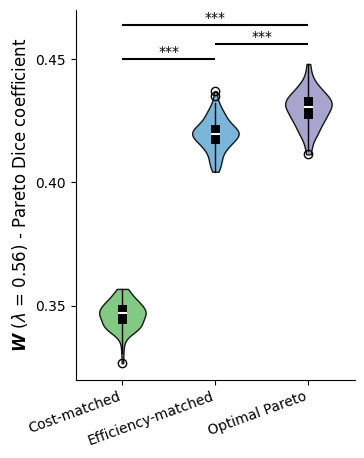

In [21]:
res = [costavg_match, effiavg_match, optimal_match]
colors = [plt.get_cmap('tab20c').colors[i] for i in [9, 1, 13]]

plt.figure(figsize = (3.6, 4.8)); ax = plt.gca()

vp = ax.violinplot(res, showextrema = False)
for i, body in enumerate(vp['bodies']):
    body.set_facecolor(colors[i])
    body.set_edgecolor('black')
    body.set_alpha(0.9)

box = ax.boxplot(res, widths = 0.1, patch_artist = True, positions = np.arange(1, 4), showcaps = False)
for patch in box['boxes']: patch.set(facecolor = 'black', linewidth = 0)
for median in box['medians']: median.set(color = 'white', linewidth = 1.5)

pvals = [wilcoxon(res[0], res[1])[1], wilcoxon(res[1], res[2])[1], wilcoxon(res[0], res[2])[1]]
_, qvals, _, _ = multipletests(pvals, alpha = 0.05, method = 'bonferroni')
sigbar(1, 2, 0.450, qvals[0])
sigbar(2, 3, 0.456, qvals[1])
sigbar(1, 3, 0.464, qvals[2])

ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xticks([1, 2, 3], ['Cost-matched', 'Efficiency-matched', 'Optimal Pareto'], rotation = 20, ha = 'right', fontsize = 10)
plt.ylabel(r'$\boldsymbol{W}$ ($\lambda$ = 0.56) - Pareto Dice coefficient', fontsize = 12); plt.ylim(0.32, 0.47); plt.yticks([0.35, 0.40, 0.45], fontsize = 10)

plt.show()

In [22]:
res = [res_human56['intra_effi'].values, [res_pareto['intra_effi'].values[costavg_idx]], [res_pareto['intra_effi'].values[effiavg_idx]], [res_pareto['intra_effi'].values[optimal_idx]]]

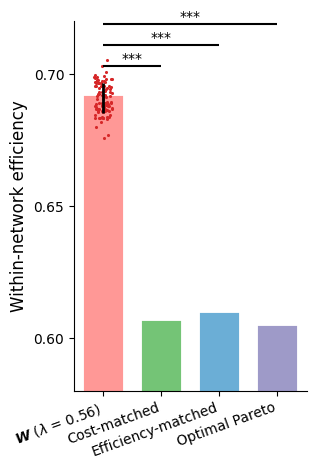

In [23]:
plt.figure(figsize = (3.0, 4.8)); ax = plt.gca()

plt.bar([0], [np.mean(res[0])], width = 0.6, color = plt.get_cmap('tab20' ).colors[ 7], edgecolor = plt.get_cmap('tab20' ).colors[ 7], linewidth = 3, zorder = 1)
plt.bar([1], [np.mean(res[1])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 9], edgecolor = plt.get_cmap('tab20c').colors[ 9], linewidth = 3, zorder = 1)
plt.bar([2], [np.mean(res[2])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 1], edgecolor = plt.get_cmap('tab20c').colors[ 1], linewidth = 3, zorder = 1)
plt.bar([3], [np.mean(res[3])], width = 0.6, color = plt.get_cmap('tab20c').colors[13], edgecolor = plt.get_cmap('tab20c').colors[13], linewidth = 3, zorder = 1)
plt.bar([0, 1, 2, 3], [np.mean(temp) for temp in res], yerr = [np.std(res[0]), 0, 0, 0], alpha = 0, zorder = 3, error_kw = {'elinewidth': 2})
jittered_x = 0 + np.random.uniform(-0.15, 0.15, size = len(res[0]))
ax.scatter(x = jittered_x, y = res[0], color = plt.get_cmap('tab20').colors[6], s = 5, linewidths = 0, zorder = 2)

pvals = [wilcoxon(res[0] - res[i][0])[1] for i in range(1, len(res))]
_, qvals, _, _ = multipletests(pvals, alpha = 0.05, method = 'bonferroni')
for i in range(1, len(res)): sigbar(0, i, 0.703+(i-1)*0.008, qvals[i-1])

ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlim(-0.5, 3.5); plt.xticks([0, 1, 2, 3], [r'$\boldsymbol{W}$ ($\lambda$ = 0.56)', 'Cost-matched', 'Efficiency-matched', 'Optimal Pareto'], rotation = 20, ha = 'right', fontsize = 10)
plt.ylabel('Within-network efficiency', fontsize = 12); plt.ylim(0.58, 0.72); plt.yticks([0.60, 0.65, 0.70], fontsize = 10)

plt.show()

In [24]:
res = [res_human56['inter_effi'].values, [res_pareto['inter_effi'].values[costavg_idx]], [res_pareto['inter_effi'].values[effiavg_idx]], [res_pareto['inter_effi'].values[optimal_idx]]]

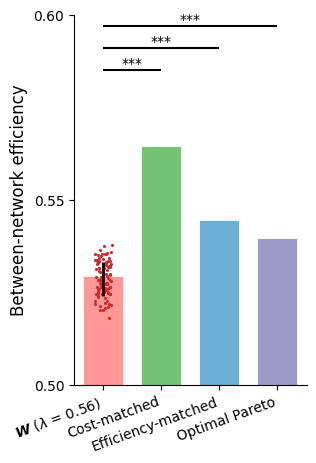

In [25]:
plt.figure(figsize = (3.0, 4.8)); ax = plt.gca()

plt.bar([0], [np.mean(res[0])], width = 0.6, color = plt.get_cmap('tab20' ).colors[ 7], edgecolor = plt.get_cmap('tab20' ).colors[ 7], linewidth = 3, zorder = 1)
plt.bar([1], [np.mean(res[1])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 9], edgecolor = plt.get_cmap('tab20c').colors[ 9], linewidth = 3, zorder = 1)
plt.bar([2], [np.mean(res[2])], width = 0.6, color = plt.get_cmap('tab20c').colors[ 1], edgecolor = plt.get_cmap('tab20c').colors[ 1], linewidth = 3, zorder = 1)
plt.bar([3], [np.mean(res[3])], width = 0.6, color = plt.get_cmap('tab20c').colors[13], edgecolor = plt.get_cmap('tab20c').colors[13], linewidth = 3, zorder = 1)
plt.bar([0, 1, 2, 3], [np.mean(temp) for temp in res], yerr = [np.std(res[0]), 0, 0, 0], alpha = 0, zorder = 3, error_kw = {'elinewidth': 2})
jittered_x = 0 + np.random.uniform(-0.15, 0.15, size = len(res[0]))
ax.scatter(x = jittered_x, y = res[0], color = plt.get_cmap('tab20').colors[6], s = 5, linewidths = 0, zorder = 2)

pvals = [wilcoxon(res[0] - res[i][0])[1] for i in range(1, len(res))]
_, qvals, _, _ = multipletests(pvals, alpha = 0.05, method = 'bonferroni')
for i in range(1, len(res)): sigbar(0, i, 0.585+(i-1)*0.006, qvals[i-1])

ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlim(-0.5, 3.5); plt.xticks([0, 1, 2, 3], [r'$\boldsymbol{W}$ ($\lambda$ = 0.56)', 'Cost-matched', 'Efficiency-matched', 'Optimal Pareto'], rotation = 20, ha = 'right', fontsize = 10)
plt.ylabel('Between-network efficiency', fontsize = 12); plt.ylim(0.50, 0.60); plt.yticks([0.50, 0.55, 0.60], fontsize = 10)

plt.show()

In [26]:
sublist = np.unique(res_human56['FILE_ID'])
edge_human = np.array([[res_human56[res_human56['FILE_ID'] == sub]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)] for sub in sublist])
edge_human = edge_human / np.array([res_human56[res_human56['FILE_ID'] == sub]['global_effi'].to_list()[0] for sub in sublist]).reshape(-1, 1)
edge_human = np.hstack([np.ones((edge_human.shape[0], 1)), edge_human, np.zeros((edge_human.shape[0], 1))])
edge_human_avg = np.mean(edge_human, axis = 0); edge_human_std = np.std(edge_human, axis = 0)

edge_pareto_costavg = np.array([res_pareto[res_pareto['index'] == costavg_idx]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)])
edge_pareto_costavg = edge_pareto_costavg / res_pareto[res_pareto['index'] == costavg_idx]['global_effi'].to_list()[0]
edge_pareto_costavg = np.array([1] + list(edge_pareto_costavg) + [0])

edge_pareto_effiavg = np.array([res_pareto[res_pareto['index'] == effiavg_idx]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)])
edge_pareto_effiavg = edge_pareto_effiavg / res_pareto[res_pareto['index'] == effiavg_idx]['global_effi'].to_list()[0]
edge_pareto_effiavg = np.array([1] + list(edge_pareto_effiavg) + [0])

edge_pareto_optimal = np.array([res_pareto[res_pareto['index'] == optimal_idx]['target_edge_attack_{:02d}_effi'.format(round(att*100))].to_list()[0] for att in np.linspace(0.05, 0.95, 19)])
edge_pareto_optimal = edge_pareto_optimal / res_pareto[res_pareto['index'] == optimal_idx]['global_effi'].to_list()[0]
edge_pareto_optimal = np.array([1] + list(edge_pareto_optimal) + [0])

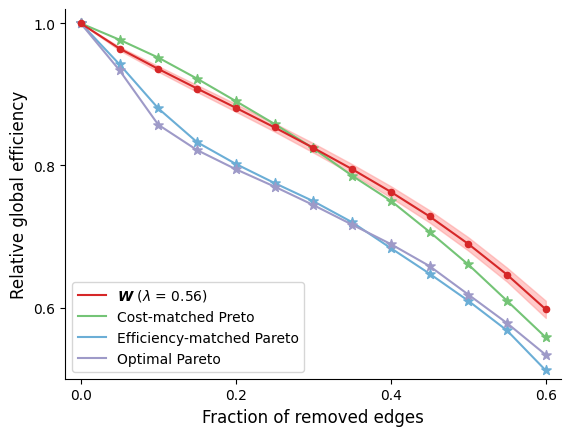

In [27]:
plt.plot(np.linspace(0, 1, 21)[:13], edge_human_avg[:13], zorder = 4, color = plt.get_cmap('tab20').colors[6], label = r'$\boldsymbol{W}$ ($\lambda$ = 0.56)')
plt.fill_between(np.linspace(0, 1, 21)[:13], edge_human_avg[:13] - edge_human_std[:13], edge_human_avg[:13] + edge_human_std[:13], zorder = 1, color = plt.get_cmap('tab20').colors[7], alpha = 0.5)
plt.scatter(np.linspace(0, 1, 21)[:13], edge_human_avg[:13], zorder = 4, color = plt.get_cmap('tab20').colors[6], s = 20)

plt.plot(np.linspace(0, 1, 21)[:13], edge_pareto_costavg[:13], zorder = 1, color = plt.get_cmap('tab20c').colors[9], label = 'Cost-matched Preto')
plt.scatter(np.linspace(0, 1, 21)[:13], edge_pareto_costavg[:13], zorder = 1, color = plt.get_cmap('tab20c').colors[9], s = 50, marker = '*')

plt.plot(np.linspace(0, 1, 21)[:13], edge_pareto_effiavg[:13], zorder = 2, color = plt.get_cmap('tab20c').colors[1], label = 'Efficiency-matched Pareto')
plt.scatter(np.linspace(0, 1, 21)[:13], edge_pareto_effiavg[:13], zorder = 2, color = plt.get_cmap('tab20c').colors[1], s = 50, marker = '*')

plt.plot(np.linspace(0, 1, 21)[:13], edge_pareto_optimal[:13], zorder = 3, color = plt.get_cmap('tab20c').colors[13], label = 'Optimal Pareto')
plt.scatter(np.linspace(0, 1, 21)[:13], edge_pareto_optimal[:13], zorder = 3, color = plt.get_cmap('tab20c').colors[13], s = 50, marker = '*')

ax = plt.gca(); ax.spines['right'].set_visible(False); ax.spines['top'].set_visible(False)
plt.xlabel('Fraction of removed edges', fontsize = 12); plt.xlim(-0.02, 0.62); plt.xticks([0.0, 0.2, 0.4, 0.6], fontsize = 10)
plt.ylabel('Relative global efficiency', fontsize = 12); plt.ylim(0.50, 1.02); plt.yticks([0.6, 0.8, 1.0], fontsize = 10)
plt.legend(loc = 'lower left', fontsize = 10)

plt.show()